Complete the exercises below For **Assignment #5**.

In this exercise, we are building a logistic regression classification model. We'll work with the [Pima Indians Diabetes Database](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database).  

Load the `tidymodels` library. 

In [1]:
library(tidymodels)

── Attaching packages ────────────────────────────────────── tidymodels 1.4.1 ──

✔ broom        1.0.13     ✔ recipes      1.3.3 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.5.1      ✔ workflows    1.3.0 
✔ parsnip      1.6.0      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 

── Conflicts ───────────────────────────────────────── tidymodels_conflicts() ──
✖ purrr::discard() masks scales::discard()
✖ dplyr::filter()  masks stats::filter()
✖ dplyr::lag()     masks stats::lag()
✖ recipes::step()  masks stats::step()



The data is located in your homework directory in the `diabetes.csv` file. Read in the data by running the following cell. We are "splitting" the data into training and testing sets. We will evaluate our model's performance with the test set.

In [4]:
diabetes = readr::read_csv('diabetes.csv') |> mutate(Outcome = factor(Outcome))

split = initial_split(diabetes, strata = Outcome)

diabetes_train = training(split)
diabetes_test = testing(split)

Rows: 768 Columns: 9
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (9): Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, D...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Glimpse the `diabetes_train` table.

In [5]:
glimpse(diabetes_train)

Rows: 576
Columns: 9
$ Pregnancies              <dbl> 10, 10, 1, 3, 8, 1, 13, 5, 6, 10, 11, 3, 7, 7…
$ Glucose                  <dbl> 115, 139, 103, 126, 99, 97, 145, 109, 92, 122…
$ BloodPressure            <dbl> 0, 80, 30, 88, 84, 66, 82, 75, 92, 78, 76, 64…
$ SkinThickness            <dbl> 0, 0, 38, 41, 0, 15, 19, 26, 0, 31, 0, 25, 18…
$ Insulin                  <dbl> 0, 0, 83, 235, 0, 140, 110, 0, 0, 0, 0, 70, 0…
$ BMI                      <dbl> 35.3, 27.1, 43.3, 39.3, 35.4, 23.2, 22.2, 36.…
$ DiabetesPedigreeFunction <dbl> 0.134, 1.441, 0.183, 0.704, 0.388, 0.487, 0.2…
$ Age                      <dbl> 29, 57, 33, 27, 50, 22, 57, 60, 28, 45, 35, 2…
$ Outcome                  <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …


❓ Which variable is suitable as the "outcome" in a logistic regression model?

** Answer:outcomes since it catagorized in 1 and 0 for if the person is debitics or not **

❓ Navigate to [Kaggle page](https://www.kaggle.com/datasets/mathchi/diabetes-data-set) for this dataset. Find descriptions for the `Glucose` and `BMI` columns. Add these descriptions to the [Markdown table](https://www.markdownguide.org/extended-syntax/#tables) below.

| Column name | Description |
| :---------- | :---------- |
| Glucose     |    plasma gelcouse concentration 2 hours before         |
| BMI         |    body mass index claculate weight diveded by hight       |

Make a bar chart showing the frequency of each "outcome" in the `Outcome` column from your `diabetes_train` data.

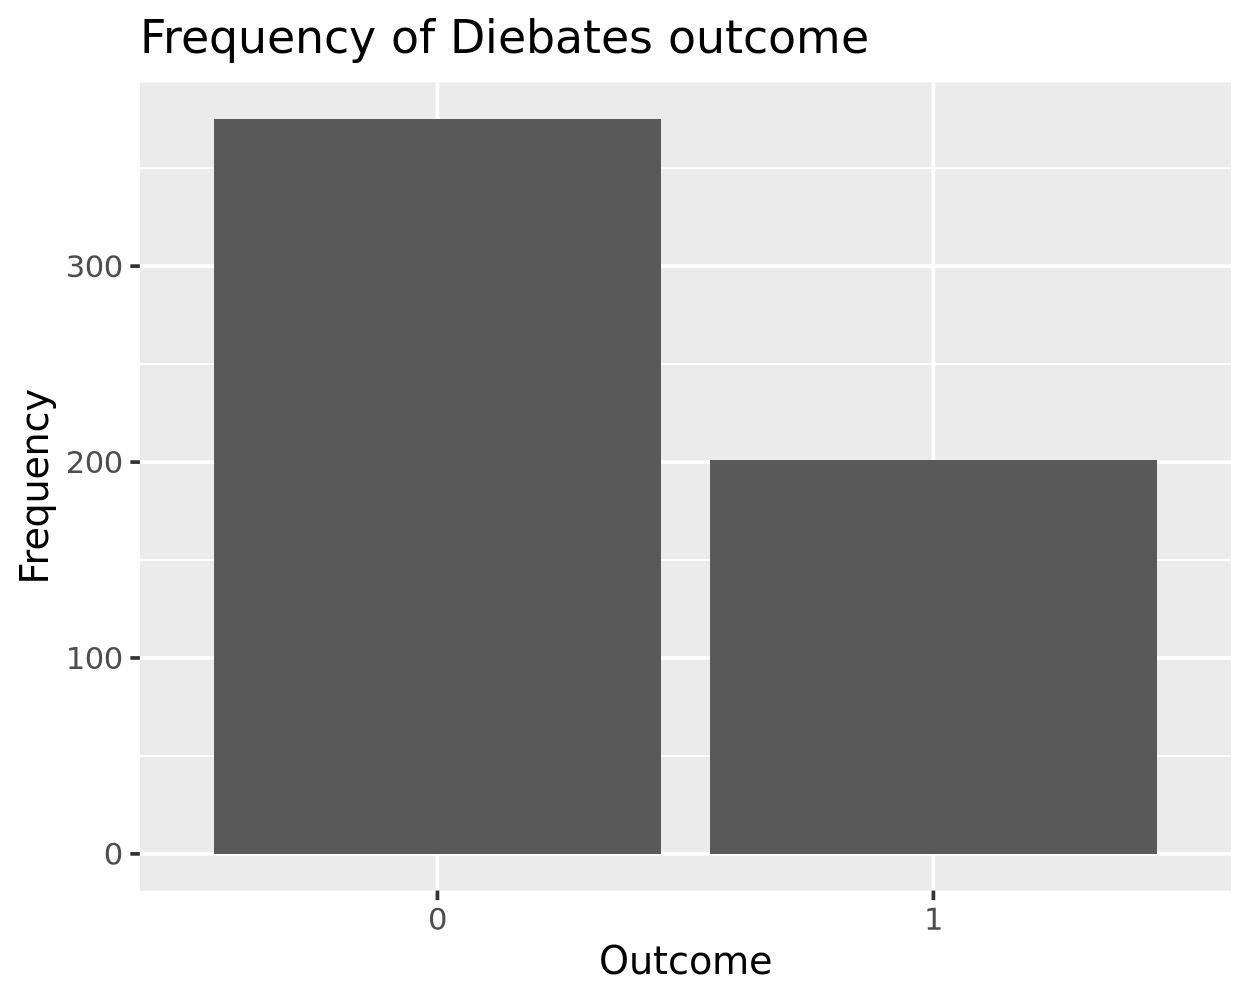

In [9]:


ggplot(diabetes_train, aes(x = Outcome))+
geom_bar()+
labs(
    title = "Frequency of Diebates outcome",
    x = "Outcome",
    y = "Frequency"
    )


❓ Is the data balanced? I.e. do we have equal counts of each outcome?

**Answer:  the data is not balanced since the out come is not same here the outcome for 0 the frequency is above 300 whlie frequency of 1 is 200. so , No the outcome is not balanced the number of no debeties(=0) is greter than the number of debeties (=1)so the two class have unbalanced or unequal counts.**

Run the code below to create a table for plotting the predictors we will use in our model: `Glucose` and `BMI`. 

In [10]:
plot_df = diabetes_train |>
    select(Outcome, Glucose, BMI) |>
    pivot_longer(cols = c(Glucose, BMI))

plot_df |> head()

Outcome,name,value
<fct>,<chr>,<dbl>
0,Glucose,115.0
0,BMI,35.3
0,Glucose,139.0
0,BMI,27.1
0,Glucose,103.0
0,BMI,43.3


Using `plot_df`, make a chart showing the relationship of `Glucose` and `BMI` with `Outcome`. 

- use `geom_jitter` for your "geom"
- `facet_wrap` your chart by the `name` variable. (e.g. `facet_wrap(~name, ncol = 2, scales = 'free_x')`)

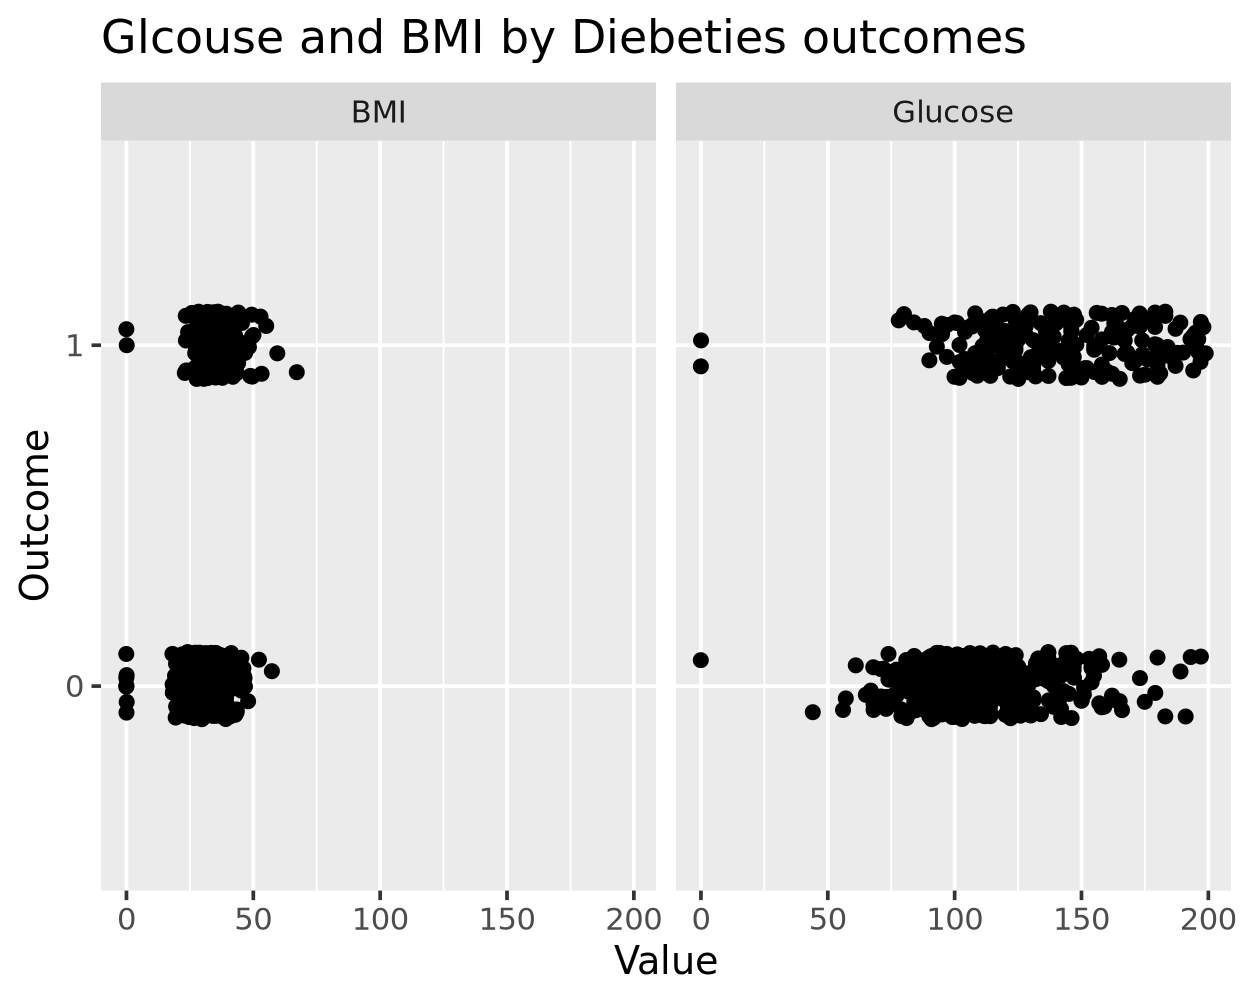

In [11]:
ggplot(plot_df, aes(x = value, y = Outcome))+
geom_jitter(height=0.1, width = 0.1)+
facet_wrap(~name, ncol = 2)+
labs(
    title = "Glcouse and BMI by Diebeties outcomes",
    x = "Value",
    y = "Outcome"
    )

❓ What happens when you remove the `scales = 'free_x'` argument from the `facet_wrap` function?

**Answer: when i removed the scales in the BMI the value moved to in beteween 0 and 50 while Glucose does not have that much shifting.**

Using your training data, build logistic regression model of `Outcome` with `BMI` and `Glucose` as predictors. 
- Use "glm" for you engine
- The formula for your fit function will be `Outcome ~ BMI + Glucose`

In [16]:
logistic_model <- glm(
    Outcome ~ BMI + Glucose,
    data = diabetes_train,
    family = binomial
    )
# i just add the head(1) to see how the model look like 
logistic_model |> head(1) 

$coefficients
(Intercept)         BMI     Glucose 
-6.93166107  0.07136231  0.03207201

Using `augment` with your fitted model and the `diabetes_test` data as arguments, create a new dataset called `diabetes_test_wPred` that is the `diabetes_test` table including predictions from your model. 

In [13]:
diabetes_test_wPred <- augment( 
    logistic_model,
    newdata = diabetes_test,
    type.predict = "response"
    )

diabetes_test_wPred |> head()


Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,.fitted
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<dbl>
1,85,66,29,0,26.6,0.351,31,0,0.09051995
1,89,66,23,94,28.1,0.167,21,0,0.11185106
5,116,74,0,0,25.6,0.201,30,0,0.20029801
4,110,92,0,0,37.6,0.191,30,0,0.32727911
1,189,60,23,846,30.1,0.398,59,1,0.78210135
7,100,0,0,0,30.0,0.484,32,1,0.17028754


In [18]:
diabetes_test_wPred <- diabetes_test_wPred |>
  mutate(
    .pred_class = factor(
      ifelse(.fitted >= 0.5, 1, 0),
      levels = c(0, 1)
    )
  )

diabetes_test_wPred |> conf_mat(truth = Outcome, estimate = .pred_class)

          Truth
Prediction   0   1
         0 356 128
         1  19  73

Run the code below to generate a confusion matrix for your model predictions. 

(❗️Hint: See Table 4.4 from [*Introduction to Statistical Learning (Version 2)*](https://www.statlearning.com/) for an example confusion matrix.)

❓ Based on the confusion matrix above, 
- How many individuals had diabetes in your test data?
- Of those that actually had diabetes, how many were predicted to have diabetes by your model?
- How many individuals predicted to have diabetes did not have diabetes?

**Answer: 128 + 73 = 201 had diabetes 73 predicted to have diabetes and 19 predicted to have diabetes did not have diabetes**